### Import libraries

In [25]:
# !pip install transformers
# !pip install librosa
# !pip install ipywidgets
# !pip install PySoundFile
# !pip install sentencepiece
# !pip install sacremoses
# !pip install soundfile
# !pip install sentencepiece

In [26]:
import torch
import librosa
import librosa.display
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display
from transformers import WhisperProcessor, WhisperForConditionalGeneration
import os
from pathlib import Path

# Speech recognition with the Whisper model

This notebook implements the speech-recognition part of the project. We prepare and analyze all audio samples, group them by difficulty, and then run two Whisper models (base and large) to compare their transcription quality and performance.



## Audio Preprocessing

We divided the audio files into three groups based on difficulty. 

-	The easy group contains clean, slow, and clearly spoken Finnish made for learners. 
-	The medium group includes normal dialogues with more natural speech and some small background sounds. 
-	The hard group has music, fast talking, and anglicisms, which makes transcription much more difficult for Whisper.


### Audio Sources

Easy group

1. opi_suomea.wav

Source: Opi suomea – Finnish lessons (YouTube)

URL: https://www.youtube.com/watch?v=3SX6qfaoJMY

Timestamp: 00:00–00:20 (beginning of the video)

2. yki3_mainos.wav

Source: YLE Kauppa mainos

URL: https://yle.fi/a/74-20082590

Timestamp: 03:00–03:10

Medium group

3. pipsapossu.wav

Source: Pipsa Possu – Rannalla

URL: https://www.youtube.com/watch?v=Tp78RwLqyZ8

Timestamp: 03:04–03:24

4. moomi.wav

Source: Comet in Moominland

URL: https://www.youtube.com/watch?v=0r75FK92NAU

Timestamp: 26:05–26:25

5. metrossa.wav

Source: Hukassa Pekingin metrossa

URL: https://www.youtube.com/watch?v=xUKVDPhEaFo

Timestamp: 04:51–05:11

Hard group

6. chahacha.wav

Source: Käärijä – Cha Cha Cha (LIVE)

URL: https://www.youtube.com/watch?v=l6rS8Dv5g-8

Timestamp: 00:45–01:05

7. some_podcast.wav

Source: Some podcast episode

URL: https://www.youtube.com/watch?v=I7pYm_SVAxA

Timestamp: 18:55–19:25


### Load audio files

In [27]:
audio_folder = Path("./audio/wav")

# Group definitions
easy_files = [
    "opi_suomea.wav",
    "yki3_mainos.wav"
]

medium_files = [
    "pipsapossu.wav",
    "moomi.wav",
    "metrossa.wav"
]

hard_files = [
    "chahacha.wav",
    "some_podcast.wav"
]

# Helper function
def load_group(file_list):
    return [str(audio_folder / f) for f in file_list]

# Load groups
easy_group = load_group(easy_files)
medium_group = load_group(medium_files)
hard_group = load_group(hard_files)

print("Easy:", easy_group)
print("Medium:", medium_group)
print("Hard:", hard_group)


Easy: ['audio\\wav\\opi_suomea.wav', 'audio\\wav\\yki3_mainos.wav']
Medium: ['audio\\wav\\pipsapossu.wav', 'audio\\wav\\moomi.wav', 'audio\\wav\\metrossa.wav']
Hard: ['audio\\wav\\chahacha.wav', 'audio\\wav\\some_podcast.wav']


### Audio playback for all groups

In [28]:
from IPython.display import Audio, display

def play_audio(file_path):
    y, sr = librosa.load(file_path, sr=16000)

    print(f"\n=== {Path(file_path).name} ===")
    print(f"Duration: {librosa.get_duration(y=y, sr=sr):.2f} seconds")
    print(f"Sample rate: {sr} Hz")

    display(Audio(y, rate=sr))


for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    print(f"\n###### {group_name} group ######")
    for file_path in group_paths:
        play_audio(file_path)



###### Easy group ######

=== opi_suomea.wav ===
Duration: 17.68 seconds
Sample rate: 16000 Hz



=== yki3_mainos.wav ===
Duration: 25.65 seconds
Sample rate: 16000 Hz



###### Medium group ######

=== pipsapossu.wav ===
Duration: 26.94 seconds
Sample rate: 16000 Hz



=== moomi.wav ===
Duration: 15.67 seconds
Sample rate: 16000 Hz



=== metrossa.wav ===
Duration: 15.39 seconds
Sample rate: 16000 Hz



###### Hard group ######

=== chahacha.wav ===
Duration: 25.81 seconds
Sample rate: 16000 Hz



=== some_podcast.wav ===
Duration: 21.64 seconds
Sample rate: 16000 Hz


### Audio Visualization


=== Easy group ===
Visualizing: opi_suomea.wav


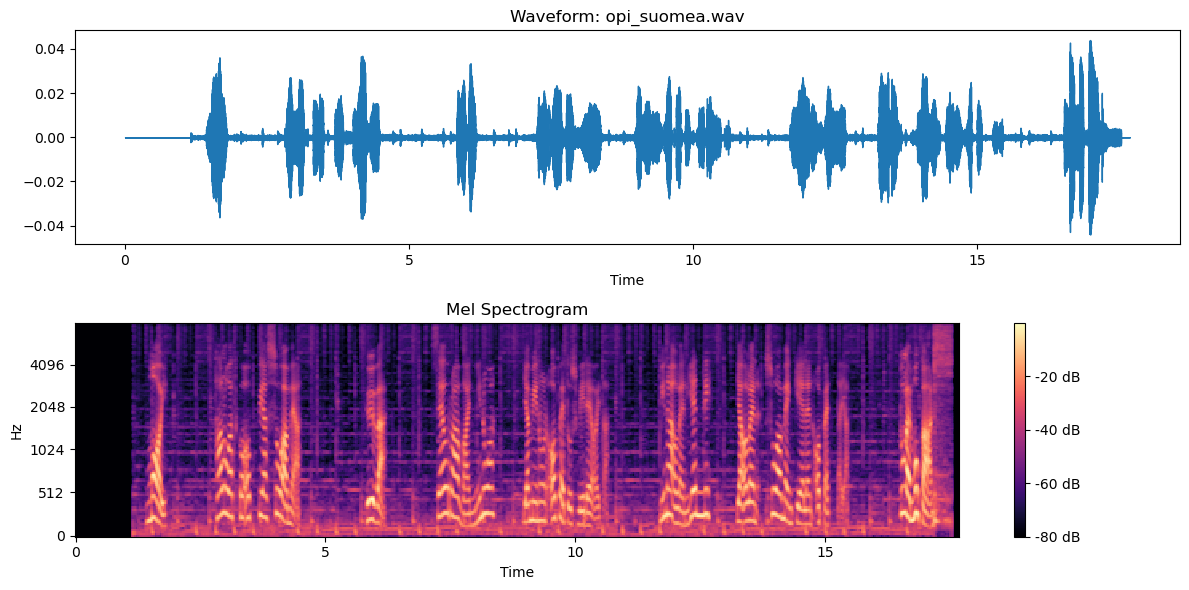

Visualizing: yki3_mainos.wav


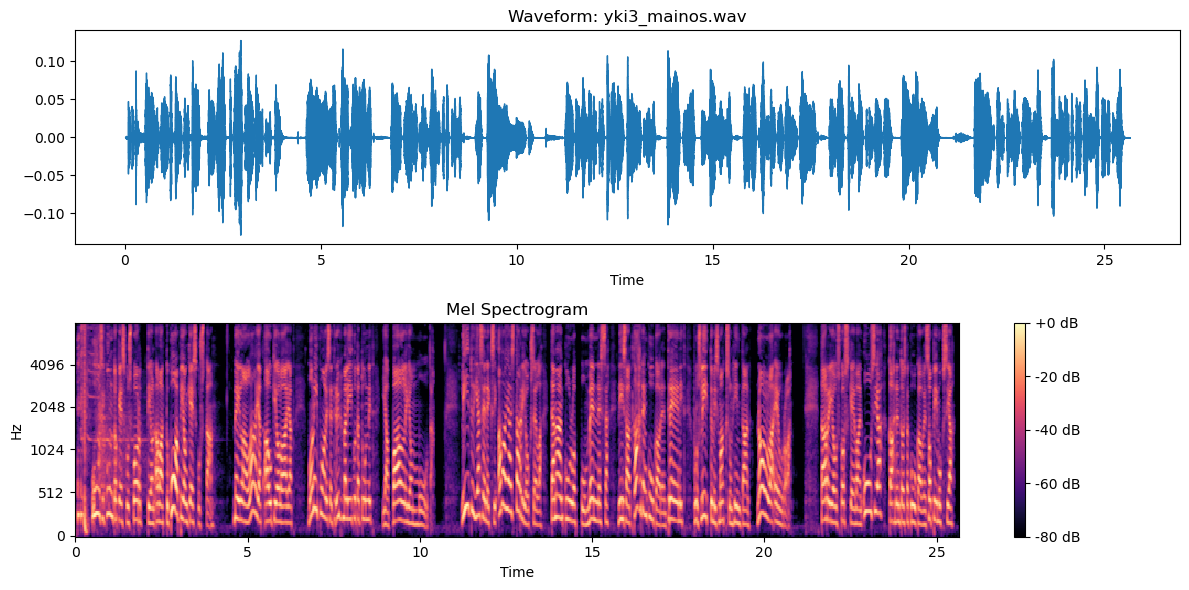


=== Medium group ===
Visualizing: pipsapossu.wav


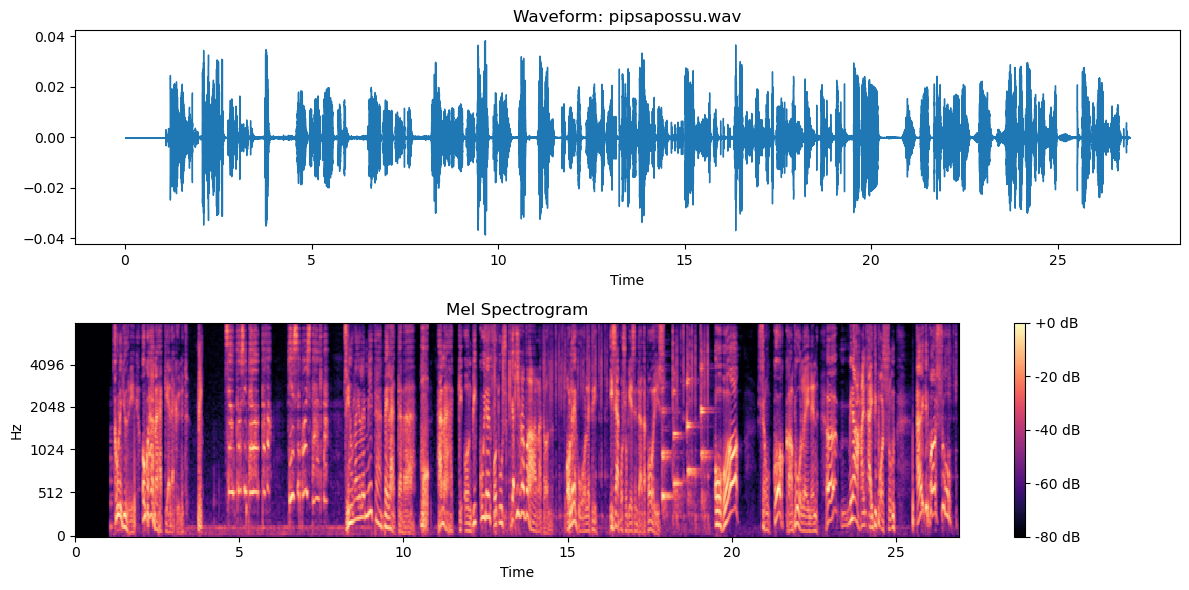

Visualizing: moomi.wav


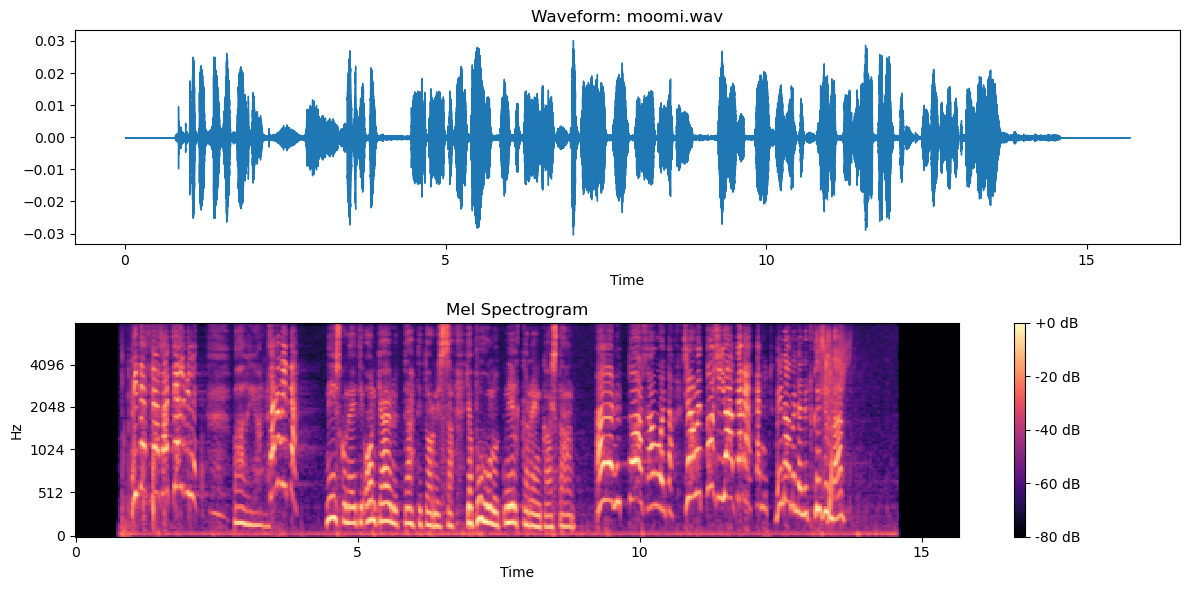

Visualizing: metrossa.wav


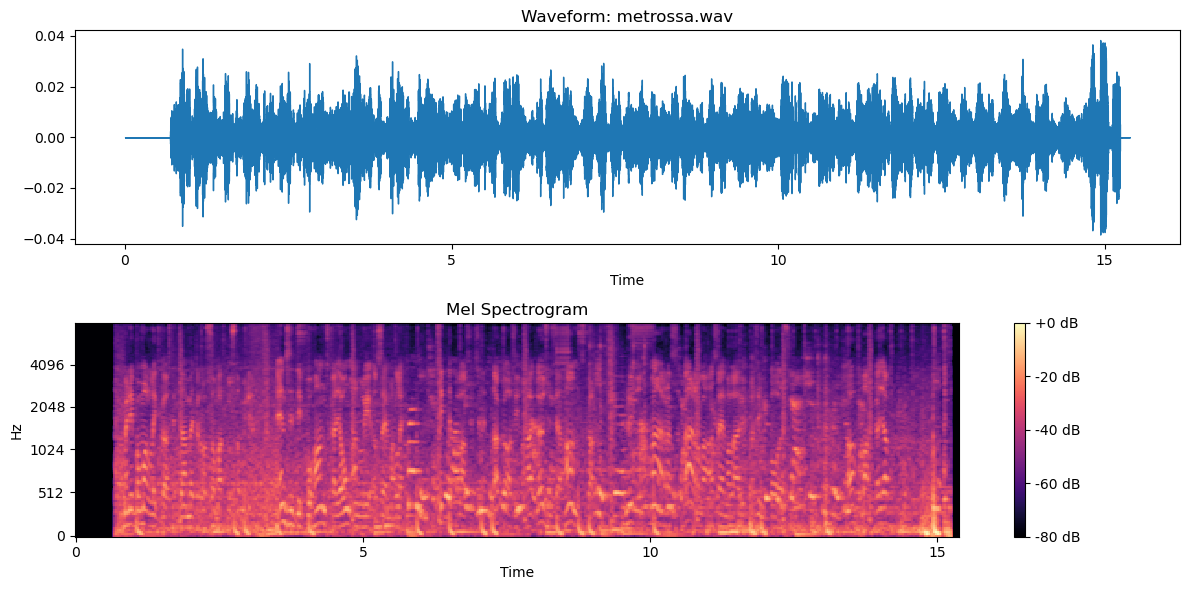


=== Hard group ===
Visualizing: chahacha.wav


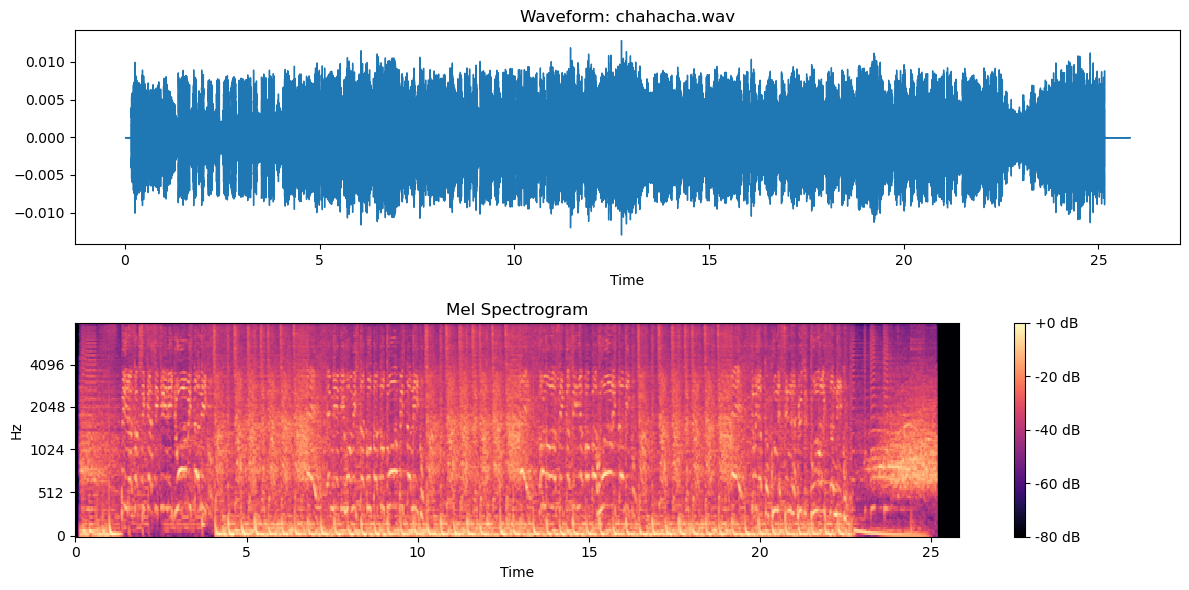

Visualizing: some_podcast.wav


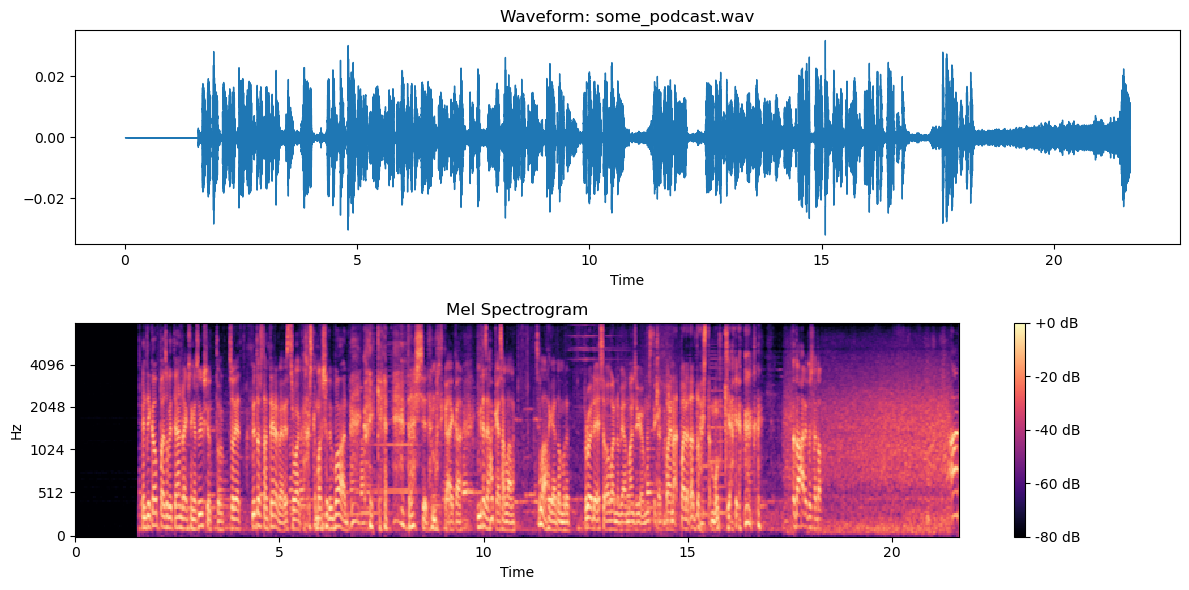

In [29]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

def visualize_audio_compact(file_path):  
    y, sr = librosa.load(file_path, sr=16000)

    fig, ax = plt.subplots(2, 1, figsize=(12, 6))

    librosa.display.waveshow(y, sr=sr, ax=ax[0])
    ax[0].set_title(f"Waveform: {Path(file_path).name}")

    S = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128)
    S_dB = librosa.power_to_db(S, ref=np.max)
    img = librosa.display.specshow(
        S_dB, 
        y_axis='mel', 
        x_axis='time', 
        sr=sr, 
        ax=ax[1]
    )
    ax[1].set_title("Mel Spectrogram")
    fig.colorbar(img, ax=ax[1], format='%+2.0f dB')

    plt.tight_layout()
    plt.show()

for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    print(f"\n=== {group_name} group ===")
    for file_path in group_paths:
        print(f"Visualizing: {Path(file_path).name}")
        visualize_audio_compact(file_path)

The visualizations show why cha cha cha is the hardest clip: the waveform is almost fully filled because music plays under fast speech, and the mel spectrogram has strong low- and mid-frequency bands from the background track. These sounds overlap with the speech features, making it difficult for Whisper to separate words and detect clear phonemes.

## Running Whisper Models on the Audio Dataset

We will create the model using both Base and Large models from Whisper separately, and later we will compare the results. First we define two functions that both base and large models use when creating a transcript.

In [30]:
# Function to process the audio
def process_audio(file_path):
    y, sr = librosa.load(file_path, sr=16000)
    # Process with WhisperProcessor
    print("Processing audio...")
    input_features = processor(
        y,
        sampling_rate=sr,
        return_tensors="pt"
    ).input_features.to(device)
    return input_features

# Creates a transcript for the audio
def create_transcript(file_path, model):
    input_features = process_audio(file_path)

    # Generate the transcription
    print("Generating transcription...")
    with torch.no_grad():
        generated_ids = model.generate(
            input_features,
            language="fi",
            task="transcribe"
        )

    # Decode the generated IDs
    transcription = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    print("\nFINNISH TRANSCRIPTION:")
    print("="*50)
    print(transcription)
    return transcription

### Base Model

The for-loop iterates through all the audio files, creates a transcription for them and saves the transcriptions to a dictionary.

In [31]:
# Initialize the model
model_size = "base"
device = "cuda" if torch.cuda.is_available() else "cpu"
device = "mps" if torch.mps.is_available() else "cpu"
print(f"Using device: {device}")

# Load model and processor
print(f"Loading Whisper {model_size} model...")
model_name = f"openai/whisper-{model_size}"
processor = WhisperProcessor.from_pretrained(model_name)
base_model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

# Set the language to Finnish
forced_decoder_ids = processor.get_decoder_prompt_ids(language="fi", task="transcribe")

base_transcriptions = {}
for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    base_transcriptions[group_name] = []
    print(f"\n=== {group_name} group ===")
    for file_path in group_paths:
        print(f"Processing: {Path(file_path).name}")
        transcription = create_transcript(file_path, base_model)
        base_transcriptions[group_name].append(transcription)

Using device: cpu
Loading Whisper base model...

=== Easy group ===
Processing: opi_suomea.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Moi, taluatko oppia Suomea? Hyvä! Seuraa vain minua ja minun opetusvideoita. Minä olen Jenni ja olen Suomen kielen opettaja. Tulemukaan!
Processing: yki3_mainos.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Uusi kuntokeskusportti on avattu kohapion keskustaa. Meillä on laajat aukiolaajat, monipuoliset ryhmäliikutatunnit ja paljon muuta. Liity jäsenäksi avaajais tarjouksella tämäen kulloppuun mennessä, niin saat kahden kuukauden treenit plus liittymis maksun hintaan nolla euroa. Tarjous koskevaan uusia, kahden toista kuukauven sopimuksia,

=== Medium group ===
Processing: pipsapossu.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Kule yri, onko hämähäkkiä näkynyt? Se on tosi pelottava, viisse pois täältä. Sinulla jolle mitään pelättävää. Huh, hämähäkki on pikkui 

The results are promising, although some transcriptions, for example for the chahacha.wav, are just nonsense.

### Large Model

The same thing is done here but using the large model. When using the larger model, the transcriptions should also be better.

In [32]:
# Initialize the model
model_size = "large"
device = "cuda" if torch.cuda.is_available() else "cpu"
device = "mps" if torch.mps.is_available() else "cpu"
print(f"Using device: {device}")

# Load model and processor
print(f"Loading Whisper {model_size} model...")
model_name = f"openai/whisper-{model_size}"
processor = WhisperProcessor.from_pretrained(model_name)
large_model = WhisperForConditionalGeneration.from_pretrained(model_name).to(device)

# Set the language to Finnish
forced_decoder_ids = processor.get_decoder_prompt_ids(language="fi", task="transcribe")

large_transcriptions = {}
for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    large_transcriptions[group_name] = []
    print(f"\n=== {group_name} group ===")
    for file_path in group_paths:
        print(f"Processing: {Path(file_path).name}")
        transcription = create_transcript(file_path, large_model)
        large_transcriptions[group_name].append(transcription)

Using device: cpu
Loading Whisper large model...

=== Easy group ===
Processing: opi_suomea.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Moi! Haluatko oppia suomea? Hyvä! Seuraa vain minua ja minun opetusvideoita. Minä olen Jenni ja olen suomen kielen opettaja. Tule mukaan!
Processing: yki3_mainos.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Uusi kuntokeskusportti on avattu Kuopion keskustaan. Meillä on laajat aukioloajat, monipuoliset ryhmäliikuntatunnit ja paljon muuta. Liity jäseneksi avajaistarjouksella tämän kuun loppuun mennessä, niin saat kahden kuukauden treenit plus liittymismaksun hintaan nolla euroa. Tarjous koskee vain uusia 12 kuukauden sopimuksia,

=== Medium group ===
Processing: pipsapossu.wav
Processing audio...
Generating transcription...

FINNISH TRANSCRIPTION:
 Kuule, Jyri, onko hämähäkkiä näkynyt? Se on tosi pelottava. Vies se pois täältä. Sinulla ei ole mitään pelättävää. Hämähäkki on pikkuinen otus j

These transcriptions are significantly better but not perfect. The algorithm seems to have problems when there's a lot of background noise, which is understandable.

## Whisper Translation (Finnish → English)

Next we try to translate the transcriptions to English using both base and large model. On top of that, we try to implement MarianMT model to do the translating. MarianMT model is dedicated to do Finnish to English translations so it should perform even better than the Whisper model.

First, we again define a function that both base and large model will use.

In [33]:
# Set the task to translate
forced_decoder_ids_translate = processor.get_decoder_prompt_ids(language="fi", task="translate")

def create_translation(file_path, model):
    input_features = process_audio(file_path)

    # Generate the translation
    print("Generating English translation...")
    with torch.no_grad():
        generated_ids = model.generate(
            input_features,
            language="en",
            task="transcribe"
        )

    # Decode the generated IDs
    translation = processor.batch_decode(
        generated_ids,
        skip_special_tokens=True
    )[0]

    print("\nENGLISH TRANSLATION:")
    print("="*50)
    print(translation)
    return translation

### Base Model Translation

In [34]:
base_translations = {}
print(f"\n\n=== Base Model Translations ===")
for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    base_translations[group_name] = []
    print(f"\n=== {group_name} group ===")
    for file_path in group_paths:
        print(f"Processing: {Path(file_path).name}")
        translation = create_translation(file_path, base_model)
        base_translations[group_name].append(translation)



=== Base Model Translations ===

=== Easy group ===
Processing: opi_suomea.wav
Processing audio...
Generating English translation...

ENGLISH TRANSLATION:
 Hello! Hello, I'm Sua. Good to meet you. I'm a teacher and I'm an student. I'm a teacher and I'm a student. Let's start!
Processing: yki3_mainos.wav
Processing audio...
Generating English translation...

ENGLISH TRANSLATION:
 The 6-second-day sport is a great sport. We have a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great team, a great

All the translations of the base model seem to be nonsense.

### Large Model Translation

In [35]:
large_translations = {}
print(f"\n\n=== Large Model Translations ===")
for group_name, group_paths in [
    ("Easy", easy_group),
    ("Medium", medium_group),
    ("Hard", hard_group)
]:
    large_translations[group_name] = []
    print(f"\n=== {group_name} group ===")
    for file_path in group_paths:
        print(f"Processing: {Path(file_path).name}")
        translation = create_translation(file_path, large_model)
        large_translations[group_name].append(translation)



=== Large Model Translations ===

=== Easy group ===
Processing: opi_suomea.wav
Processing audio...
Generating English translation...

ENGLISH TRANSLATION:
 Hi! Do you want to learn Finnish? Good! Follow only me and my teaching videos. I am Jenny and I am a Finnish language teacher. Come along!
Processing: yki3_mainos.wav
Processing audio...
Generating English translation...

ENGLISH TRANSLATION:
 A new city centre has been opened in the centre of Kuopio. We have large open hours, multi-faceted group hours and much more. Join the open offer this end of the month so you can get two months of training plus a membership fee of 0 euros. The offer will only include new 12-month contracts,

=== Medium group ===
Processing: pipsapossu.wav
Processing audio...
Generating English translation...

ENGLISH TRANSLATION:
 Jyri, have you seen a spider? It's really scary. Take it away. You have nothing to be afraid of. Spider is a small creature and very harmless. Don't worry, I'll take the father be

The large model performs a lot of better again, but it still makes some mistakes. For example, it translates "kuntokeskusportti" to "city centre".

### MarianMT Model Translation

In [36]:
from transformers import MarianMTModel, MarianTokenizer

# Using a dedicated Finnish to English translation model
def create_better_translation(transcription):
    model_name = "Helsinki-NLP/opus-mt-fi-en"
    translation_tokenizer = MarianTokenizer.from_pretrained(model_name)
    translation_model = MarianMTModel.from_pretrained(model_name)

    # Translate the Finnish transcription
    inputs = translation_tokenizer(transcription, return_tensors="pt")
    translated = translation_model.generate(**inputs)
    better_translation = translation_tokenizer.decode(translated[0], skip_special_tokens=True)

    print("BETTER ENGLISH TRANSLATION:")
    print("="*50)
    print(better_translation)
    return better_translation


better_translations = {}
print(f"\n\n=== Better Translations ===")
for group_name, transcription_list in large_transcriptions.items():
    better_translations[group_name] = []
    print(f"\n=== {group_name} group ===")
    for i, transcription in enumerate(transcription_list):
        print(f"\nProcessing transcript #{i+1} in {group_name}...")
        translation = create_better_translation(transcription)
        better_translations[group_name].append(translation)



=== Better Translations ===

=== Easy group ===

Processing transcript #1 in Easy...
BETTER ENGLISH TRANSLATION:
Hi! Do you want to learn Finnish? Good! Just follow me and my teaching videos. I am Jenni and I am a Finnish teacher. Come with me!

Processing transcript #2 in Easy...
BETTER ENGLISH TRANSLATION:
The new multi-gym gate has been opened in the centre of Kuopio. We have extensive opening hours, versatile group exercise classes and much more. Join with the opening offer by the end of this month, and you will receive two months of training plus a fee of zero euros.

=== Medium group ===

Processing transcript #1 in Medium...
BETTER ENGLISH TRANSLATION:
Look, Jyri, have you seen a spider? It's really scary. Get it out of here. You have nothing to fear. Spider is a tiny creature and completely harmless.

Processing transcript #2 in Medium...
BETTER ENGLISH TRANSLATION:
What are you gonna find out? Tell me what! The snort lady has been to the tower and talked about her ankle ring

This translation model is by far the best. The "chahacha.wav" seems to still be a huge problem to these models to both transcript and translate.

## Evaluation of Whisper Base vs. Large Models

### Experimental setup

One of our Team Members recorded and selected seven Finnish audio clips and grouped them into three difficulty levels:

- **Easy**: clear, studio-like speech with nearly no background noise (Finnish teaching video, gym commercial).
- **Medium**: children’s TV audio and speech with some background sounds and more informal language.
- **Hard**: a live performance with loud music under fast speech, and a noisy segment.

Each clip was transcribed with both the **Whisper base** and **Whisper large** models, and then translated from Finnish to English. Goal here was to compare the models by quality and understand where the larger model brings actual benefits.

### Finnish transcriptions

#### Easy group

For the easy clips, both models perform well. The main messages of the language-learning introduction and the gym commercial are captured correctly by both base and large. The sentences are grammatical, the speaker is correctly introduced, and the commercial text mostly matches the original content.  

In this setting, the difference between base and large is small: the large model sometimes uses slightly more natural wording or fixes minor inflection mistakes, but overall both outputs would be usable as transcripts.

**Conclusion for easy audio:** when the audio is clean, the speech is slow and clearly articulated and there is almost no background noise, the base model is already sufficient and the large model does not add much visible value.

#### Medium group

In the medium group (children’s programmes and “metrossa” clip), the situation changes. Here we have faster, more emotional speech, informal language and some background noise.

- The **base model** still produces text that is mostly readable, but it makes more noticeable mistakes: it occasionally drops or changes words, and some sentences become slightly confusing.
- The **large model** keeps the structure of the dialogue better. Named entities and key phrases are more often correct and the sentences remain coherent and close to the original story even when the speech is fast or overlapping.

**Conclusion for medium audio:** as soon as the audio becomes less “perfect”, the large model starts to pull ahead. It handles informal speech and moderate noise better and preserves the meaning of the dialogue more reliably than the base model.

#### Hard group

The hard group is where the difference is at its largest. Both clips contain heavy background noise: loud music in the Cha Cha Cha performance and a busy soundscape in the podcast.

- For the **Cha Cha Cha** clip, the **base model** essentially fails: the output degenerates into repeated nonsense words and does not reflect the lyrics at all.  
- The **large model** is far from perfect, but it atleast produces Finnish words and short phrases that somewhat resemble the original content. The transcript is not directly usable, but it is clearly closer to real speech than the base output.
- For the **podcast** clip, the **base model** again mixes up many words and produces strange phrases that do not match the storyline. The **large model** manages to reconstruct a coherent narrative about going to the store and discussing healthy food, which aligns with the original audio.

**Conclusion for hard audio:** with strong background noise and overlapping sounds, the base model breaks down completely, while the large model still produces partially correct and semantically meaningful text.

### Translation quality (Finnish → English)

The same pattern appears in the translation task:

- The **base model’s translations** are almost unusable. For several clips it falls into repetition loops (repeating the same phrase dozens of times) and the English text no longer corresponds to the Finnish transcript.
- The **large model’s translations** are much more reasonable. For all Easy and Medium clips it produces fluent English sentences that preserve the original meaning (Do you want to learn Finnish…, the gym offer in Kuopio, the children’s TV dialogues, and the metro story).  
- In the Hard group, the large model still makes mistakes, but it manages to keep at least the main idea of the podcast clip, where as the base model’s outputs are largely nonsense.

When we compare both Whisper models to the dedicated MarianMT translation model, MarianMT still gives the best English output overall. However, between the two Whisper variants, the large model is clearly closer to MarianMT, while the base model often completely loses the meaning.

### Why is the large model better?

These observations are consistent with what we expect from the model architectures:

- The **large model** has **more parameters** and has been trained on **more audio-text pairs**.  
- This increased capacity helps it
  - separate speech from background noise,
  - model long-range dependencies in spoken sentences,
  - generalise better to informal, fast and noisy Finnish speech.

The **base model** can handle only the simplest case: clean, slowly spoken audio. As soon as the conditions move closer to real-life situations (children speaking, public transport, music in the background), it starts to hallucinate words, repeat phrases and lose the original meaning, while the large model remains reasonably robust.

### Summary

- For **clean, studio-quality speech**, both base and large Whisper models work well, and the base model is usually good enough.
- For **more realistic audio with noise, fast speech or multiple speakers**, the **large model clearly outperforms the base model** in both transcription and translation quality.
- In the **most difficult clips with heavy background noise**, the base model effectively fails, whereas the large model still produces partially correct and interpretable text.


##### Use of AI

AI was mainly used for language corrections and for checking the logic of the solution.